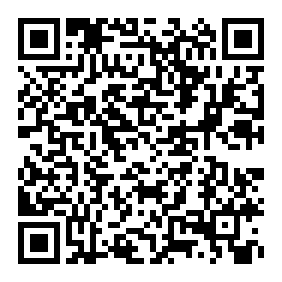

# Reactant, Enzyme, Impulse: portable performance, gradients, and Bayesian inference for scientific code as written

Presenter: Siyuan Brant Qian (siyuanq4@illinois.edu)<br>
PI: William S. Moses (wsmoses@illinois.edu)<br>
Computer Science, University of Illinois Urbana-Champaign<br>
Affiliated with the [NSF-Simons AI Institute for the Sky (SkAI)](https://skai-institute.org)

Scientists write code for many tasks, such as simulating oceans, modeling galaxies, and imaging black holes. Making that code fast, running it on accelerators such as GPUs and TPUs, or fitting it to data and quantifying uncertainty usually means rewriting it, either by hand or by porting it to a framework such as JAX, PyTorch, Stan, or Turing. For large existing codes, that rewrite is often impractical. We develop open-source compilers that take the code scientists already have and make it fast, run it on accelerators, fit it to data, and quantify uncertainty, with no rewrite.

| | |
|---|---|
| **Reactant** | compiles existing code for CPUs and accelerators, such as NVIDIA and AMD GPUs, Google TPUs, and Amazon Trainium chips, and optimizes it along the way |
| **Enzyme** | differentiates entire programs written in C, C++, Fortran, Rust, Swift, Julia, or Python (JAX) |
| **Impulse** | builds probabilistic programming into the compiler: write the model the way the science reads, get fast, general, portable Bayesian inference |

### From source code to hardware

A scientist brings existing code, written in Julia, Python (JAX), or C, C++, Fortran, Rust, or Swift. Our compilers add what the science needs: Enzyme computes gradients, Impulse performs Bayesian inference, and Reactant optimizes the whole program. The compiled program runs on the hardware available: CPUs, NVIDIA and AMD GPUs, Google TPUs, or Amazon Trainium. The scientist maintains a single version of the code for all of these devices.

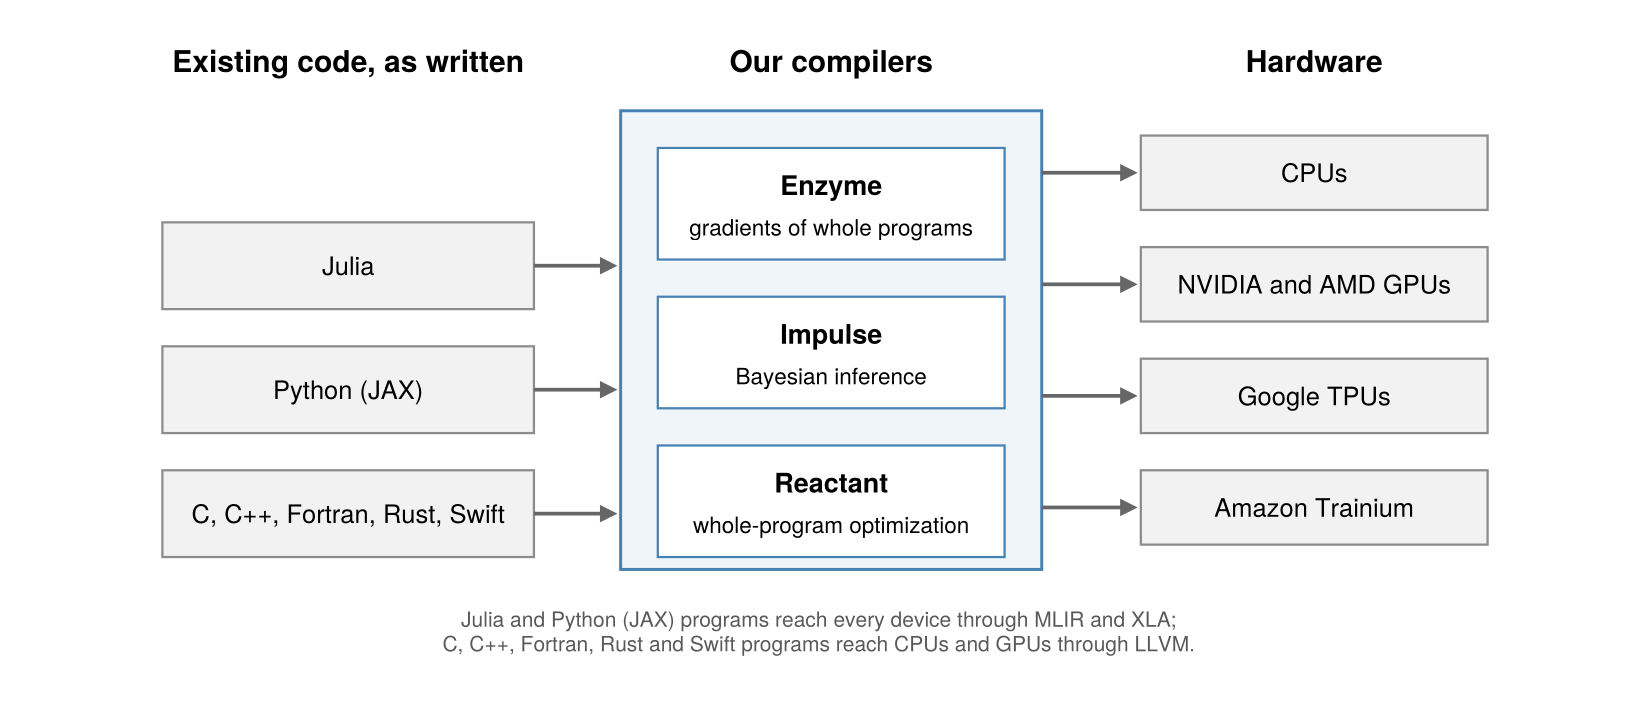

## Setup

In [ ]:
if any(occursin("COLAB"), keys(ENV))
    using Downloads
    tok = get(ENV, "SAIL_GITHUB_TOKEN", "")
    include(Downloads.download("https://raw.githubusercontent.com/PRONTOLab/sail2026-demo/main/colab/colab_setup.jl";
        headers = isempty(tok) ? Pair{String, String}[] : ["Authorization" => "Bearer $tok"]))
end
include("demo_utils.jl")
prepare_demo!()

## Reactant: one line compiles existing code for GPUs and TPUs

Running on a GPU or TPU normally means rewriting code in CUDA or in an AI framework. With Reactant, scientists add one line, `@jit`, and the compiler does the rest: Reactant compiles the ordinary function, as written, for the hardware available, and optimizes the whole program along the way. The examples here are in Julia; Python (JAX) programs reach the same optimizing compiler through [Enzyme-JAX](https://github.com/EnzymeAD/Enzyme-JAX).

In [2]:
f(x) = sum(abs2, sin.(x) .* exp.(-x .^ 2))    # ordinary Julia: nothing GPU-specific

x = rand(Float32, 10_000_000)                 # ten million numbers
x_gpu = Reactant.to_rarray(x)                 # the same numbers, on the GPU

@jit f(x_gpu)                                 # the one added line

ConcretePJRTNumber{Float32, 1}(994038.56f0)

In [3]:
cpu_vs_gpu(f, x, x_gpu)

CPU:   155.96 ms   answer 994038
GPU:     0.06 ms   answer 994039


one added line: 2617× faster, same answer


### A real ocean model

The same approach works on a full scientific code. [Oceananigans](https://github.com/CliMA/Oceananigans.jl) (Wagner et al.) is an ocean model for climate research, built from hand-written, CUDA-style GPU kernels. A CUDA compiler runs each kernel separately, as written, and only on NVIDIA GPUs. **Reactant instead raises each kernel to a higher-level form: operations on whole arrays, in the same tensor representation as the rest of the model. In that form, the compiler optimizes the kernels together with the rest of the model and targets other hardware, such as TPUs, with no rewrite.**

For intuition, here is a small kernel in the same style, one heat-diffusion step on an 8 × 8 grid, and the form Reactant raises the kernel to:

**As written: one GPU thread per grid point**

```julia
@kernel function diffuse!(T_new, T, κ)
    i, j = @index(Global, NTuple) .+ 1        # this thread's grid point
    T_new[i, j] = T[i, j] + κ * (T[i+1, j] + T[i-1, j] + T[i, j+1] + T[i, j-1] - 4T[i, j])
end
```

**After raising: operations on whole arrays (Reactant's output, renamed for reading)**

```
%center = stablehlo.slice %T [1:7, 1:7]      // every grid point at once
%east   = stablehlo.slice %T [2:8, 1:7]      // every east neighbor at once
%west   = stablehlo.slice %T [0:6, 1:7]
%north  = stablehlo.slice %T [1:7, 2:8]
%south  = stablehlo.slice %T [1:7, 0:6]
%0 = stablehlo.add %north, %south
%1 = stablehlo.add %0, %east
%2 = stablehlo.add %1, %west
%3 = stablehlo.multiply %center, -4.0
%4 = stablehlo.add %2, %3
%5 = stablehlo.multiply %4, 0.1
%6 = stablehlo.add %center, %5
%T_new = stablehlo.dynamic_update_slice %T_new, %6, [1, 1]
```

The arithmetic of one thread became five shifted copies of the whole grid, added together. In this form the compiler sees what the kernel computes, not how GPU threads split the work, so the compiler can optimize the kernel together with the rest of the model and compile the result for any supported hardware.

The model, exactly as Oceananigans users write the model: the grid, the physics, and the starting state, with cold water to the south and warm water to the north.

In [4]:
grid = RectilinearGrid(ReactantState(); size = (96, 96, 8), halo = (6, 6, 3),
    x = (0, 1000kilometers), y = (-500kilometers, 500kilometers), z = (-1kilometers, 0),
    topology = (Periodic, Bounded, Bounded))

model = HydrostaticFreeSurfaceModel(grid; coriolis = BetaPlane(latitude = -45),
    buoyancy = BuoyancyTracer(), tracers = :b,
    momentum_advection = WENOVectorInvariant(), tracer_advection = WENO(),
    free_surface = SplitExplicitFreeSurface(grid; substeps = 50))

front(x, y, z) = 4e-6 * z + 5e-3 * clamp(y / 50kilometers + 1/2, 0, 1) + 5e-5 * randn()   # cold south, warm north
set!(model, b = front);

Oceananigans doesn't need a code rewrite to run through Reactant, and Setup already compiled the time stepping. The next cell runs 25 days of ocean on the GPU and plays the sea surface as a looping animation: the swirls are ocean eddies forming.


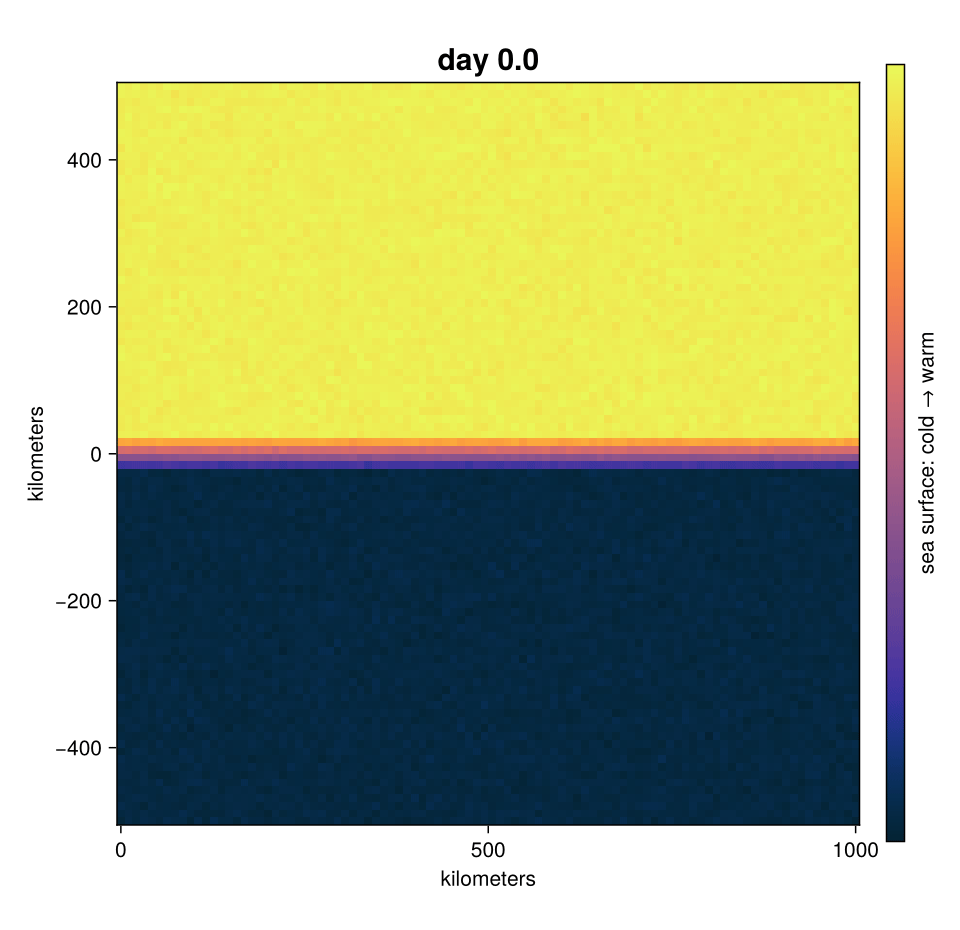

25 days of ocean, 1800 time steps: 1.3 s on one GPU


In [5]:
run_ocean!(model; days = 25)

### At supercomputer scale

The same code scales to whole supercomputers, with no porting ([GB-25](https://github.com/PRONTOLab/GB-25), Moses et al.). Reactant ran the model on **1,280 Google TPU chips**, which cannot run GPU kernels at all, by raising the kernels to whole-array operations, and on **4,096 NVIDIA GPUs** of NERSC's Perlmutter. On Perlmutter, Reactant's optimizations, including automatically choosing more efficient communication patterns between GPUs, made the model **10× to 100× faster** than the same compiled code without them. Choosing these patterns is a complex performance-tuning task that experts in high-performance computing normally do by hand. Spreading a function across many devices takes two more lines, and the function itself does not change:

```julia
# 8 devices, arranged as a 2×4 grid
mesh = Sharding.Mesh(reshape(Reactant.devices(), 2, 4), (:x, :y))
# split the data across the grid
x = Reactant.to_rarray(data; sharding = Sharding.NamedSharding(mesh, (:x, :y)))
# the same f as before, now on all 8 devices
@jit f(x)
```

## Enzyme: gradients of existing code

Gradients let scientists fit a model to data, find the best design, or put a simulation inside machine learning. Normally that means writing a second program by hand, or porting the code to a framework. **With Enzyme, scientists add one call to the code they already have.** That one call gives fast, compiler-optimized gradients of existing code in C, C++, Fortran, Rust, Swift, Julia, or Python (JAX). The examples here are Julia packages.

### The idea: follow the slope downhill

A derivative tells how a result changes when an input changes. On a landscape, the derivative is the slope, and stepping against the slope leads downhill into a valley. Fitting a model to data works the same way, with thousands of parameters instead of one. One line asks Enzyme for the slope of an ordinary function:


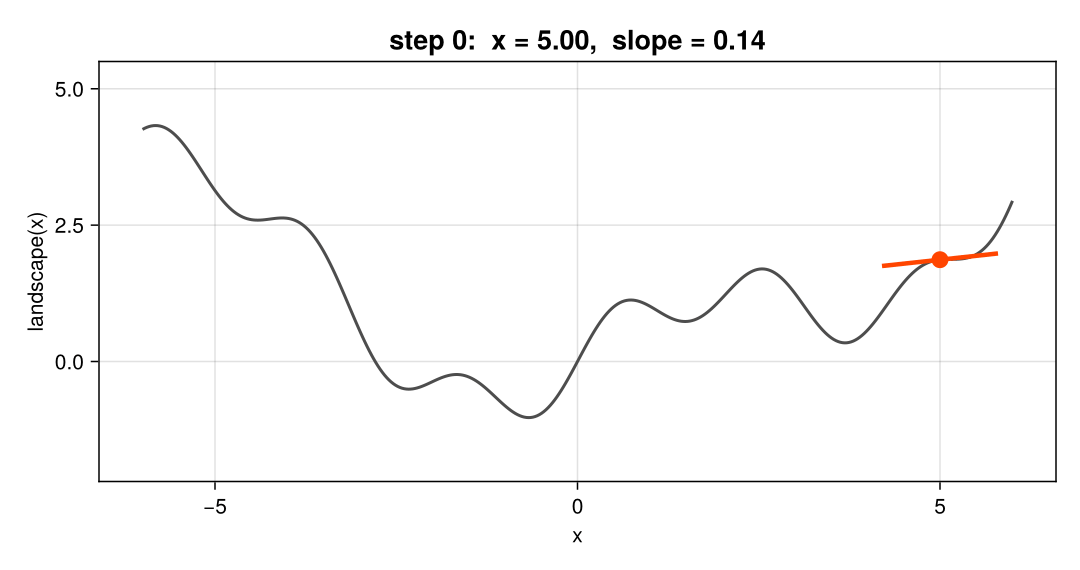

In [6]:
landscape(x) = 0.1x^2 + sin(x) + 0.5sin(3x)              # an ordinary function: a hilly landscape
slope(x) = Enzyme.gradient(Reverse, landscape, x)[1]     # its derivative, computed by Enzyme

x = 5.0                                                  # start near a hilltop
for step in 0:15
    show_step(landscape, slope, x; title = "step $step")  # one frame: the landscape, the point, the slope
    x -= 0.15 * slope(x)                                  # step downhill
end
show_animation()                                          # the frames, as a looping animation

Enzyme gave the slope at every step, from the function's own code. The same call works on whole programs with many inputs.

### A galaxy model, differentiated as written

Enzyme differentiates through real-world scientific workloads. [SkyMatch.jl](https://github.com/PRONTOLab/SkyMatch.jl) (Sathia et al.) is an astronomy model of how bright galaxies are, built on Reactant, so the same code runs on CPUs, GPUs and TPUs. Without Enzyme, finding how sensitive SkyMatch's predictions are to one parameter means rerunning the model again and again, or deriving the answer by hand. With Enzyme, one call on SkyMatch's own code gives the sensitivity of every galaxy at once. Here is SkyMatch's calculation:

```julia
function luminosities(theta, galaxies, params, noise, sfr2lir)
    varied = merge(params, (sigma_MS = sum(theta),))       # theta: the parameter
    return sfr2lir .* SkyMatch.generate_sfr(galaxies.redshift, galaxies.mstar, varied, noise).SFR
end
```

And here is the one Enzyme call, for **1,024 galaxies**:

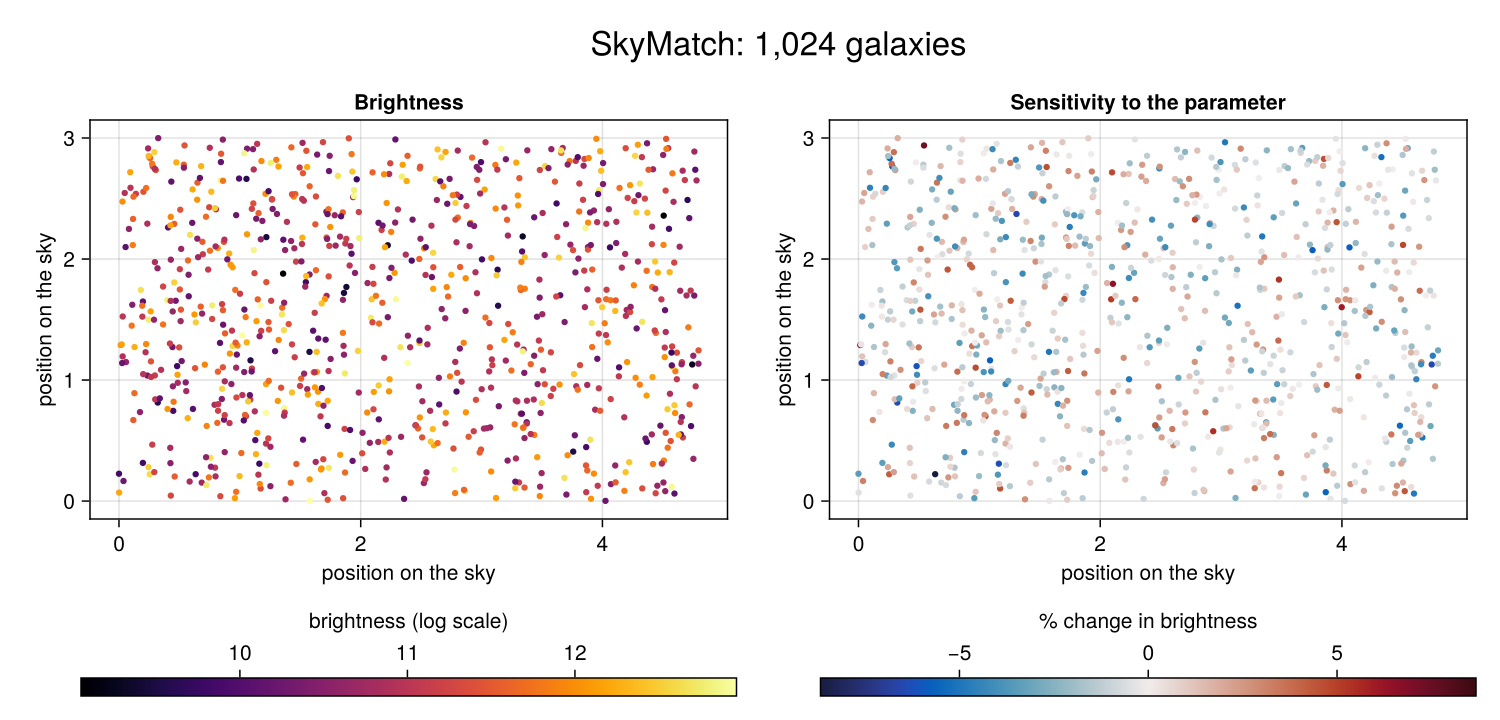

In [7]:
galaxies, params, noise, sfr2lir = synthetic_galaxies(1024)       # 1,024 galaxies
theta = [params.sigma_MS]                                          # the parameter

lir  = luminosities(theta, galaxies, params, noise, sfr2lir)       # how bright each galaxy is
dlir = Enzyme.autodiff(Forward, luminosities, Duplicated, Duplicated(theta, [1.0]),
    Const(galaxies), Const(params), Const(noise), Const(sfr2lir))[1]   # how each brightness responds, in one call

show_skymatch(galaxies, lir, dlir)

Left: how bright each galaxy is. Right: how each galaxy's brightness changes as the parameter grows; red galaxies get brighter, blue ones dimmer. Next, the same idea on an entire imaging package.

### Imaging a black hole

The first image of a black hole, M87\*, came from the **Event Horizon Telescope** (EHT) in 2019 (Event Horizon Telescope Collaboration et al.). The image was computed by fitting a model to telescope measurements, like these from one night in April 2017:

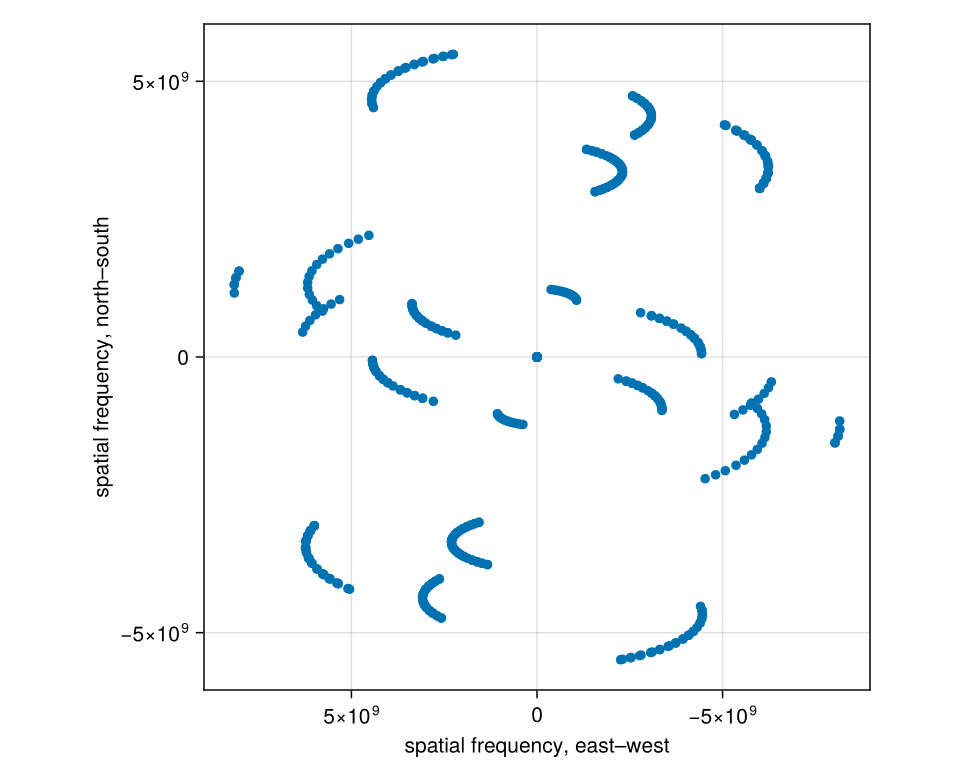

[Comrade.jl](https://github.com/ptiede/Comrade.jl) (Tiede) is an imaging package that turns radio-telescope measurements into images of the sky. The black-hole model in Comrade has **2,635 parameters** and is built from several libraries. **Comrade doesn't need a code rewrite to run on a GPU or to compute gradients.** Reactant compiles the package for the GPU, and Enzyme computes the gradient through all of the package's libraries. Comrade's tutorial builds the model in a few lines; the last line combines the sky, the telescopes, and the data:

```julia
post = VLBIPosterior(skym, intmodel, dvis)     # sky model, telescope model, and data
```

This loop starts from a random image and follows the gradient for 5,000 steps. Each step calls Enzyme once for the gradient of the whole model, then takes one step with AdamW, a standard optimizer. Setup compiled the step for the GPU:

```julia
function opt_step(opt, post, x)
    res = Enzyme.gradient(Enzyme.ReverseWithPrimal, Const(logdensityof), Const(post), x)   # Enzyme: the gradient
    opt, x = Optimisers.update!(opt, x, -res.derivs[2])                                     # AdamW: one step
    return opt, x, res.val
end
fit_step = @compile opt_step(opt, tpostr, x)
```


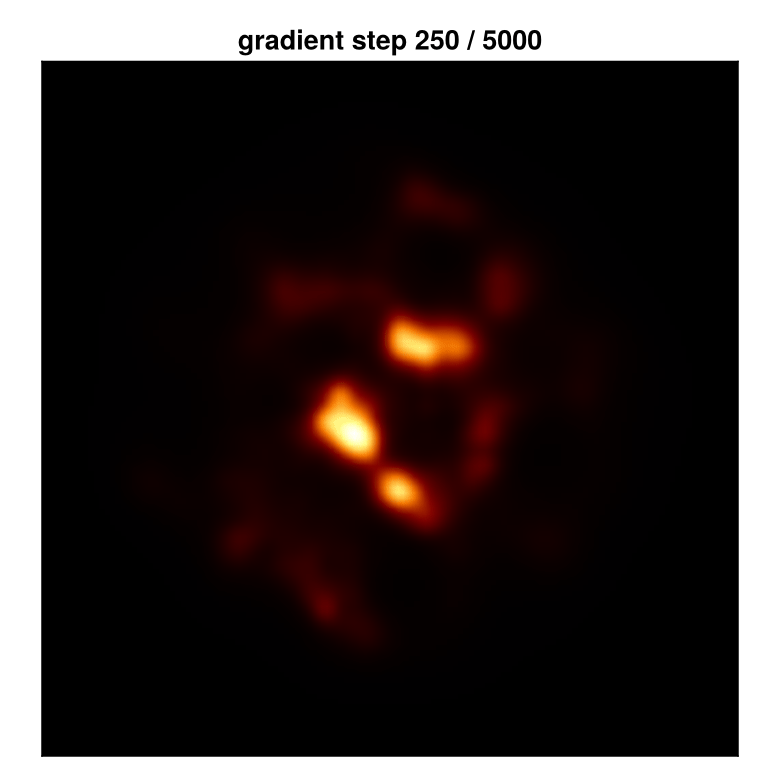

In [8]:
x = Reactant.to_rarray(prior_sample(StableRNG(42), tpost))     # a random starting image, on the GPU
opt = opt_setup(AdamW(0.01), x)
for step in 1:5000
    opt, x, logp = fit_step(opt, tpostr, x)                     # Enzyme gradient of all of Comrade, then one AdamW step
    step % 250 == 0 && show_sky(x; title = "gradient step $step / 5000")   # one frame of the animation
end
show_animation()                                                # the frames, as a looping animation

The image forms in seconds on one GPU, and every step used Enzyme's gradient of the entire package.

## Impulse: Bayesian inference, compiled

Bayesian inference estimates a model's unknown parameters from noisy observed data, and quantifies the uncertainty in each estimate. Inference programs are complex numerical code, and each new model usually needs dedicated engineering effort to make inference correct and fast. **Impulse builds Bayesian inference into the compiler, so existing models get fast inference directly.** Being compiler-based, Impulse is language-agnostic.

### The black-hole image

For the black hole, Impulse compiles the entire sampler into one GPU program:

```julia
sample(post, ReactantNUTS(), 1000)     # Impulse's sampler, as one GPU program
```

We drew 80 samples on one GPU, ten per call:

```julia
state = ProbProg.load_state(WARM_STATE)                    # the sampler, tuned once
for chunk in 1:8
    (samples, _, _, _, state) = nuts(state, tpostr, 10)    # ten more samples, on the GPU
    append!(imgs, sky_images(samples))                     # as images
end
```

On the left, one sample: one image consistent with the data. On the right, the average of all samples so far.

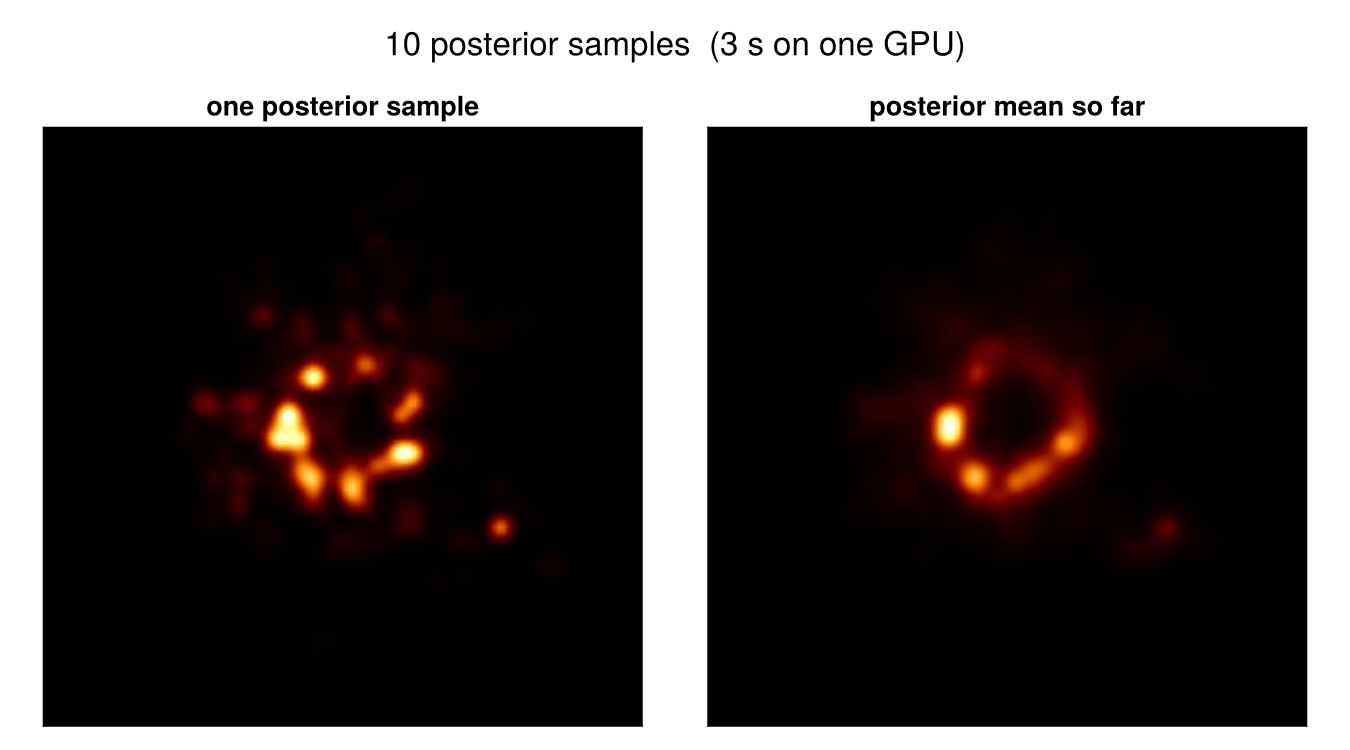

### A textbook model, made fast by the compiler

Impulse also makes inference fast without hand-tuning. A textbook example (model m14.10 from McElreath's *Statistical Rethinking*) asks whether primates that live in larger social groups have larger brains, after accounting for body size and similarities across 151 species. The model takes fixed biological data as input: how closely related each pair of species is.

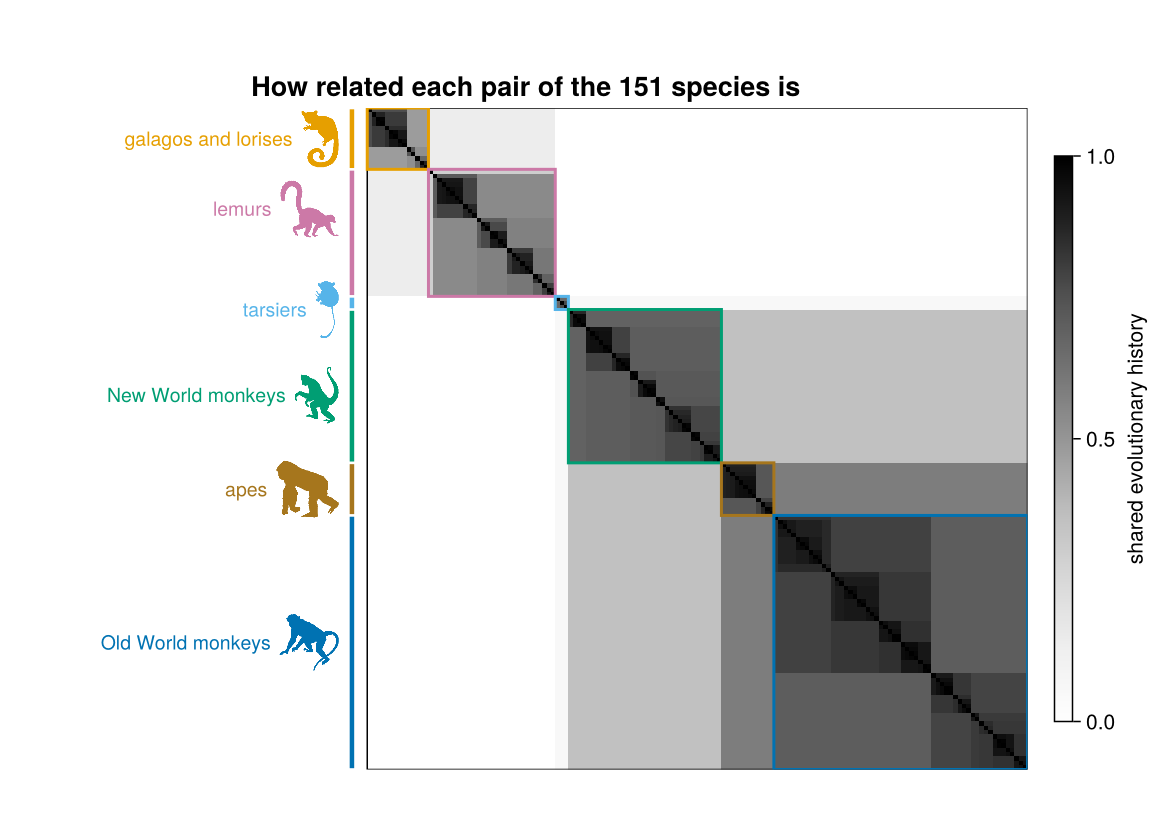

#### The model, as the textbook writes it

The same few lines in every framework:

**Impulse (Julia)**

```julia
@model function primates(M, G, R)
    a  ~ Normal(0.0, 1.0)
    bM ~ Normal(0.0, 0.5)
    bG ~ Normal(0.0, 0.5)
    sigma_sq ~ Exponential(1.0)

    mu    = a .+ bM .* M .+ bG .* G
    SIGMA = R .* sigma_sq

    B ~ MvNormal(mu, SIGMA)
end
```

**NumPyro (Python)**

```python
def primates(M, G, R, B):
    a  = numpyro.sample("a", dist.Normal(0.0, 1.0))
    bM = numpyro.sample("bM", dist.Normal(0.0, 0.5))
    bG = numpyro.sample("bG", dist.Normal(0.0, 0.5))
    sigma_sq = numpyro.sample("sigma_sq", dist.Exponential(1.0))

    mu    = a + bM * M + bG * G
    SIGMA = R * sigma_sq

    numpyro.sample("B", dist.MultivariateNormal(mu, SIGMA), obs=B)
```

**Turing (Julia)**

```julia
@model function primates(M, G, R, B)
    a  ~ Normal(0.0, 1.0)
    bM ~ Normal(0.0, 0.5)
    bG ~ Normal(0.0, 0.5)
    sigma_sq ~ Exponential(1.0)

    mu    = a .+ bM .* M .+ bG .* G
    SIGMA = R .* sigma_sq

    B ~ MvNormal(mu, SIGMA)
end
```

Written this way, every evaluation repeats an expensive computation on `SIGMA`, a 151 × 151 matrix, **thousands of times**.

#### To make it fast, the model is rewritten by hand

To make the model fast, an expert in numerical methods normally rewrites the model by hand. The expensive step is factoring `SIGMA` (a Cholesky decomposition) at every evaluation. Because `SIGMA` is the fixed relatedness matrix `R` times one unknown scale, `sigma_sq`, the expert factors `R` **once**, before sampling, and every evaluation only rescales that stored factor. The rewrite is the same in any framework. In Stan, for example, following Stan's documentation:

**Stan, as the textbook writes it**

```stan
model {
  ...
  SIGMA = R * sigma_sq;
  B ~ multi_normal(mu, SIGMA);
}
```

**Stan, rewritten by hand**

```stan
transformed data {
  matrix[N, N] L_R = cholesky_decompose(R);
}
model {
  ...
  B ~ multi_normal_cholesky(mu, sqrt(sigma_sq) * L_R);
}
```

That takes linear-algebra insight, is easy to get wrong, and the model no longer reads like the science. **With Impulse, scientists skip that rewrite.**

#### Live: Impulse runs the textbook code

Impulse runs the textbook code, timed right here: same model, same data, same sampler; only the compiler optimizations differ. Each call runs 1,000 warm-up and 3,000 posterior draws.

optimizations off: 8.67 s, on: 0.38 s: same code, 23× faster


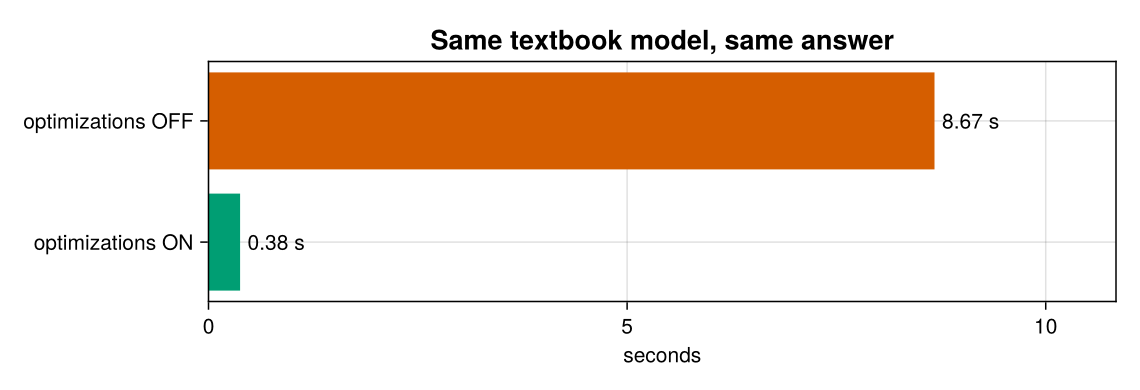

In [9]:
t_off = @elapsed draws_off = sample_textbook_model(optimizations = false)
t_on  = @elapsed draws_on  = sample_textbook_model(optimizations = true)
@printf "optimizations off: %.2f s, on: %.2f s: same code, %.0f× faster\n" t_off t_on t_off / t_on
race_figure(t_off, t_on)

**The textbook model doesn't need a code rewrite to run fast: the compiler found the expert's rewrite by itself.** (The compiler turned `cholesky(R * sigma_sq)` into `sqrt(sigma_sq) * cholesky(R)` and moved `cholesky(R)` out of the loop, because `R` never changes.)

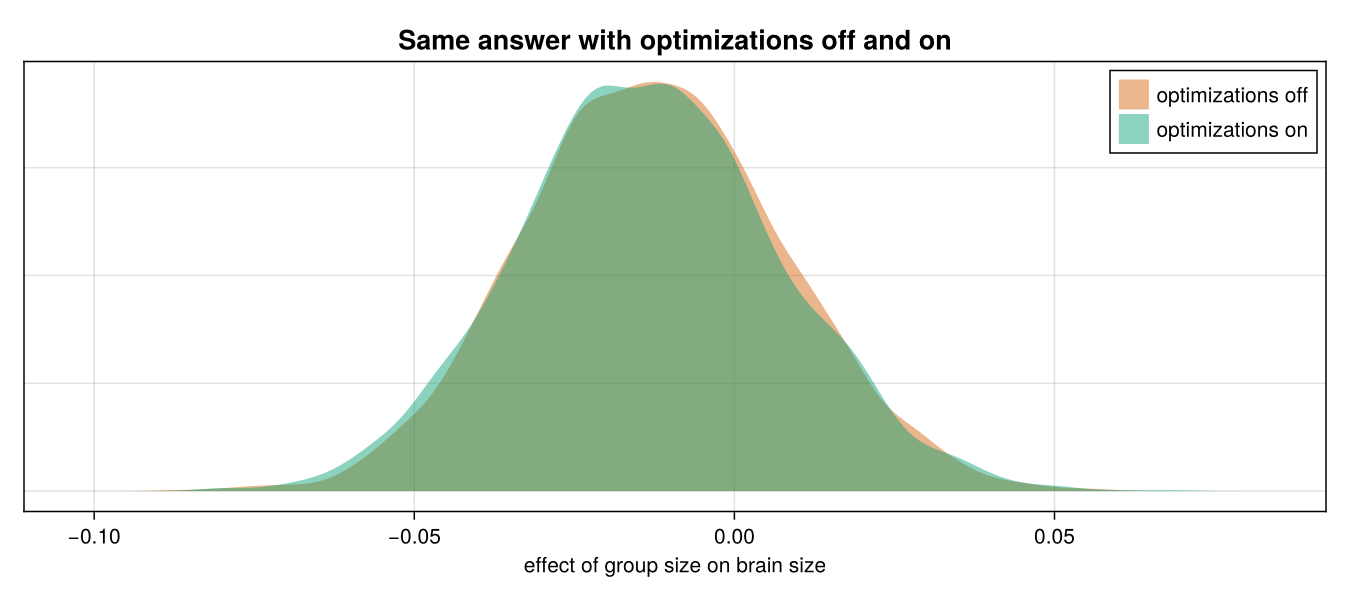

In [10]:
show_answer(draws_off, draws_on)

Optimizations off and on give the same answer: the compiler automates the expert's rewrite without changing the result.

#### Against other frameworks

On this model, on one CPU core, Impulse is 48× faster than NumPyro, 101× faster than Stan, and 156× faster than Turing, with the same answer, from the textbook code.

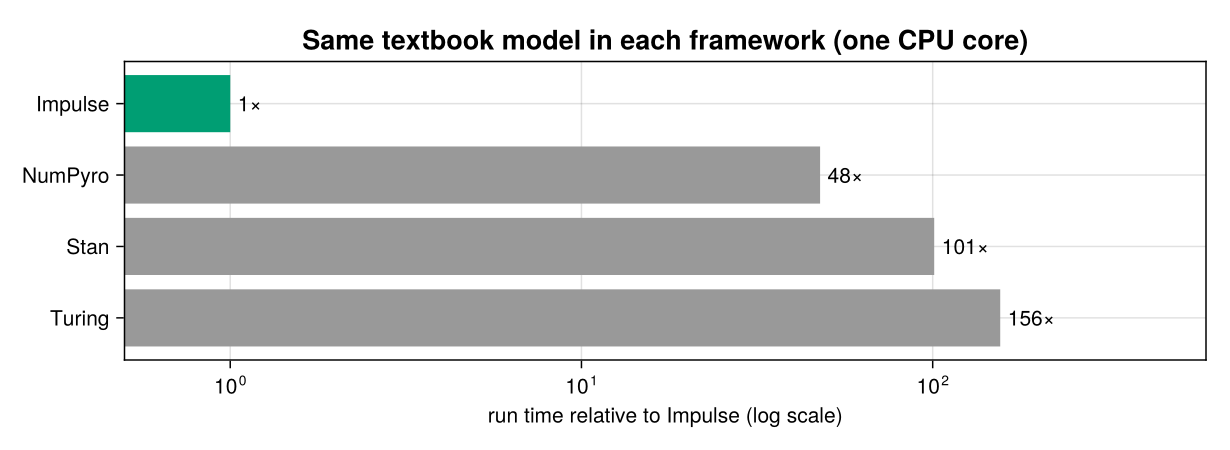

**How it works.** Impulse makes sampling and inference part of the compiler, so the compiler optimizes the model itself before building the inference algorithm.

## Takeaways

- **No rewrite.** Scientists keep their code and their language: an ocean model, a galaxy model, and an entire black-hole imaging package ran as written.
- **The same code on CPUs and accelerators, compiler-optimized.** Reactant compiles existing code, hand-written GPU kernels included, for CPUs, GPUs and TPUs: the same ocean model ran on one GPU and on over a thousand TPUs, and Reactant's optimizations made the model 10× to 100× faster on 4,096 GPUs.
- **Compiler-generated gradients of existing code.** Enzyme differentiates programs written in C, C++, Fortran, Rust, Swift, Julia, or Python (JAX), with compiler optimizations, on production scientific workloads.
- **Fast, general, and portable compiler-based Bayesian inference.** Impulse ran the entire black-hole sampler as one GPU program, and automates the rewrite that experts in numerical methods do by hand: the textbook model ran about 20× faster from the same code, and 48× to 156× faster than NumPyro, Stan and Turing.

## Try it

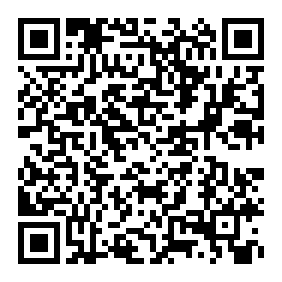

```julia
] add Reactant Enzyme
using Reactant, Enzyme
x = Reactant.to_rarray(data)              # the data, on the GPU or TPU
@jit f(x)                                 # the function, compiled
@jit Enzyme.gradient(Reverse, f, x)       # its gradient
```

Scan the QR code to [open this notebook, with all outputs, in Google Colab](https://colab.research.google.com/github/PRONTOLab/sail2026-demo/blob/main/SAIL2026_demo.ipynb).

Open-source on GitHub!

| | |
|---|---|
| Reactant.jl | https://github.com/EnzymeAD/Reactant.jl |
| Probabilistic programming (Impulse) tutorial | https://enzymead.github.io/Reactant.jl/stable/tutorials/probprog/ |
| Enzyme (C, C++, Fortran, Rust, Swift, Julia, Python (JAX), ...) | https://enzyme.mit.edu |
| Comrade.jl (black-hole imaging) | https://github.com/ptiede/Comrade.jl |
| Neural networks with Lux and Reactant (Colab notebook) | https://colab.research.google.com/drive/1UobcFjfwDI3N2EXvH3KbRS5ZxY9Riy4y |